# 04 - Grounded SAM

Runs the pipeline live on one dev image, then loads the full evaluation. Rescoring here uses the base SigLIP model, since LoRA is not implemented.

In [1]:
import pandas as pd
from IPython.display import Image, display
RESULTS = "../docs/results/"
FIGURES = "../docs/figures/"
pd.set_option("display.width", 200, "display.max_columns", 30)

## Natural-language prompt to masks

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from openwarehouse.config import load_config
from openwarehouse.experiments import image_path, load_image, load_manifest
from openwarehouse.pipeline import PerceptionPipeline
from openwarehouse.utils import resolve_device

os_root = __import__("os")
os_root.chdir("..")
config = load_config("open_images", "poc")
manifest = load_manifest(config)
image_id = "00a1c9247cf3e24c"
split = manifest[manifest["image_id"] == image_id]["split"].iloc[0]
image = load_image(image_path(config, split, image_id))
pipeline = PerceptionPipeline(config, device=resolve_device(config["device"]))
instances = pipeline(image, "person", min_score=0.32)
print([(i.label, round(i.score, 3), round(i.encoder_score, 4), int(i.mask.sum())) for i in instances])
os_root.chdir("notebooks")

C:\Users\Cudlino\Desktop\Dev\csp-vibe-code\cst620_week8\OpenWarehouse-Perception\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Loading weights:   9%|▉         | 86/978 [00:00<00:01, 852.39it/s]

Loading weights:  18%|█▊        | 172/978 [00:00<00:03, 252.34it/s]

Loading weights:  22%|██▏       | 218/978 [00:00<00:02, 291.96it/s]

Loading weights:  98%|█████████▊| 959/978 [00:00<00:00, 1851.78it/s]

... (14 outputs left out)

Loading weights:  28%|██▊       | 87/314 [00:00<00:00, 671.46it/s]

Loading weights:  49%|████▉     | 155/314 [00:00<00:00, 236.92it/s]

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 500.76it/s]

[('person', 0.907, 0.0, 73037)]


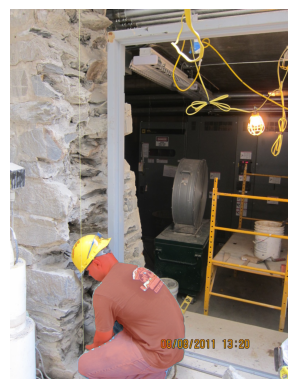

In [3]:
plt.imshow(image)
for instance in instances:
    overlay = np.zeros((*instance.mask.shape, 4))
    overlay[instance.mask] = (0.9, 0.2, 0.1, 0.45)
    plt.imshow(overlay)
plt.axis("off")
plt.show()

## Detection by prompt condition (held-out)

In [4]:
detector = pd.read_csv(RESULTS + "detector_heldout.csv")
detector.dropna(subset=["ap50"]).pivot(index="class_name", columns="condition", values="ap50").round(3)

condition,article,bare,context,descriptive,photo,synonym
class_name,,,,,,
Box,0.348,0.435,0.302,0.279,0.207,0.332
Ladder,0.428,0.553,0.430,0.205,0.307,0.341
Person,0.490,0.651,0.346,0.274,0.132,0.313
Shelf,0.169,0.161,0.109,0.105,0.094,0.139
Truck,0.462,0.463,0.468,0.418,0.377,0.409


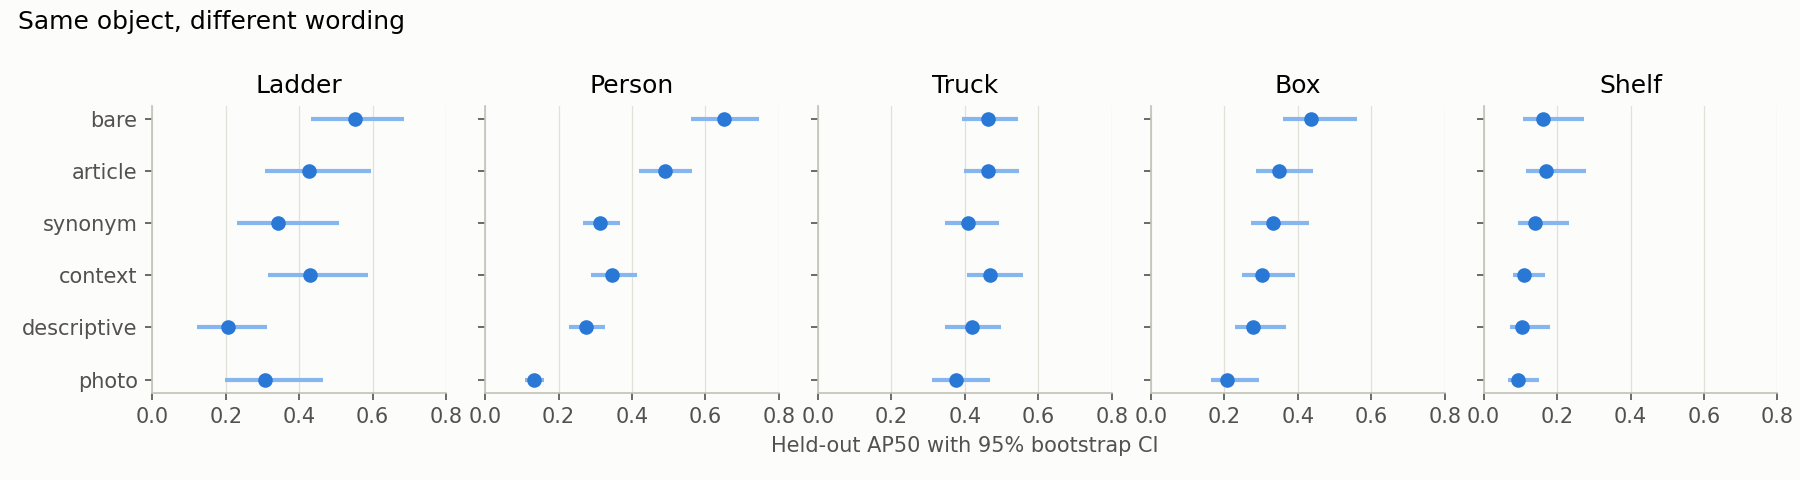

,class_name,images,ap50_bare,ap50_article,delta_low,delta_high
0,Person,941,0.651,0.490,0.128,0.195
1,Box,217,0.435,0.348,0.032,0.153
2,Shelf,438,0.161,0.169,-0.027,0.009
3,Truck,252,0.463,0.462,-0.065,0.060
4,Ladder,152,0.553,0.428,0.041,0.185


In [5]:
display(Image(FIGURES + "prompt_sensitivity_ap50.png"))
pd.read_csv(RESULTS + "ap50_bare_vs_article_heldout.csv").round(3)

## Operating point at the frozen threshold

In [6]:
pd.read_csv(RESULTS + "operating_point_heldout.csv").round(3)

,class_name,n_pos,n_neg,precision,recall,false_positive_rate
0,Aisle,86,53,0.622,0.977,0.962
1,Box,185,125,0.622,0.881,0.792
2,Cardboard,126,22,0.848,0.976,1.000
3,Forklift truck,25,14,0.641,1.000,1.000
4,Hard hat,17,22,0.436,1.000,1.000
5,Inventory,31,72,0.297,0.968,0.986
6,Ladder,117,106,0.646,0.795,0.481
7,Person,420,532,0.777,0.971,0.220
8,Shelf,298,186,0.661,0.980,0.806
9,Shelving,121,52,0.700,0.926,0.923


## Masks and rescoring

The ground-truth-box column is the upper bound for SAM. Person has only 40 instances.

In [7]:
masks = pd.read_csv(RESULTS + "masks_heldout.csv")
masks.groupby("class_name")[["oracle_box_mask_iou", "detected_mask_iou", "detected_box_iou"]].mean().round(3)

,oracle_box_mask_iou,detected_mask_iou,detected_box_iou
class_name,,,
Box,0.839,0.678,0.746
Person,0.765,0.720,0.895
Truck,0.894,0.744,0.809


In [8]:
pd.concat([pd.read_csv(RESULTS + f"rescoring_{r}.csv") for r in ("dev", "heldout")]).round(3)

,role,class_name,images,detector_ap50,siglip_only_ap50,fused_ap50
0,dev,Person,617,0.618,0.493,0.530
1,dev,Box,148,0.500,0.483,0.529
2,dev,Shelf,252,0.298,0.214,0.278
3,dev,Truck,175,0.519,0.375,0.473
4,dev,Ladder,136,0.794,0.579,0.803
0,heldout,Person,941,0.582,0.393,0.446
1,heldout,Box,217,0.428,0.464,0.524
2,heldout,Shelf,438,0.160,0.122,0.156
3,heldout,Truck,252,0.463,0.407,0.507
4,heldout,Ladder,152,0.550,0.360,0.501
